In [4]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import os

import jlinops


# Add files up one level to the path
import sys
sys.path.append("../")

from wavelets import WaveletTransformOperator2D

In [5]:
# Get both
cameraman_img = jlinops.cameraman()


image = np.zeros_like(jlinops.cameraman())
img_shape = image.shape
ground_truth = image.flatten()


# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
np.random.seed(0)
L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
coeffs = np.zeros(L.shape[0])
num_nonzero = 100
indices = np.random.choice(len(coeffs), size=num_nonzero, replace=False)
coeffs[indices] = 1
randhaar_image = (L.T @ coeffs).reshape(img_shape)
# ground_truth = image.flatten()

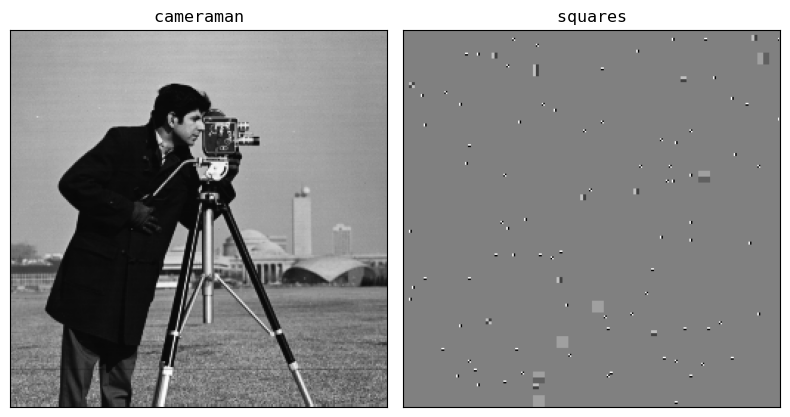

In [7]:
fig, axs = plt.subplots(1,2,figsize=(8,5))

axs[0].imshow(cameraman_img, vmin=0, vmax=1, cmap="gray")
axs[0].set_title("$\\mathtt{cameraman}$")
axs[0].set_xticks([])
axs[0].set_yticks([])

axs[1].imshow(randhaar_image, cmap="gray")
axs[1].set_title("$\\mathtt{randhaar}$")
axs[1].set_xticks([])
axs[1].set_yticks([])

fig.tight_layout()
fig.savefig("wavelet_ground_truths.png", dpi=250, bbox_inches="tight")
fig.savefig("wavelet_ground_truths.eps", format="eps", dpi=250, bbox_inches="tight")

plt.show()